# MSCS 634 – Project Deliverable 2
## Regression Modeling and Performance Evaluation
**Project:** Advanced Data Mining for Data-Driven Insights and Predictive Modeling
**Student:** Ruchitha Musku
**Dataset:** IBM Telco Customer Churn, cleaned in Deliverable 1 (7,043 customers)

---
### Contents
1. Problem definition: choosing the outcome variable
2. Load the cleaned data and prepare the baseline features
3. Feature engineering
4. Modelling setup: train/test split, pipelines and cross-validation
5. Regression models: Linear (baseline), Multiple Linear (engineered), Ridge, Lasso, and a Random Forest benchmark
6. Model evaluation: R², MSE, RMSE, MAE on cross-validation and the held-out test set
7. Visual comparison of model performance
8. Model interpretation (coefficients, Lasso feature selection)
9. Extension: predicting customer tenure
10. Summary of results and insights

## 1. Problem Definition

**Outcome variable: `TotalCharges`**, the total revenue a customer has generated over their relationship with the company
(a "customer value to date" measure).

**Business question:** *Given a customer's profile, contract, services and tenure, how much revenue have they generated?*
An accurate revenue model is useful for:
- estimating the value of customer segments and the revenue at risk when customers churn;
- forecasting revenue for new customers as their tenure grows;
- detecting billing anomalies (large residuals mean a bill that does not match the customer's plan).

**Predictors:** demographics, tenure, contract, billing/payment and the nine service columns.

**Excluded to prevent data leakage:**
- `MonthlyCharges`: TotalCharges is essentially tenure × MonthlyCharges, so including it would let the model reproduce the
  answer from a near-copy of the target. Without it, the model must *learn* what each service costs from the service columns.
- `Churn` / `Churn_flag`: churn status is an outcome observed at the same time as the target, not a driver of past revenue.

Deliverable 1 showed that `TotalCharges` is right-skewed (skew 0.96), strongly correlated with `tenure` (r = 0.83),
and that the predictors are correlated with each other. That motivates the feature engineering and regularisation used below.

## 2. Load the Cleaned Data

In [1]:
# --- Imports -----------------------------------------------------------------
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_validate, validation_curve, learning_curve
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titleweight"] = "bold"
pd.set_option("display.max_columns", None)
os.makedirs("figures", exist_ok=True)

RANDOM_STATE = 42   # fixed seed so every split and result is reproducible

In [2]:
# --- Load the cleaned dataset produced in Deliverable 1 -----------------------
df = pd.read_csv("data/telco_churn_cleaned.csv")
print("Shape:", df.shape)
print("Missing values:", int(df.isnull().sum().sum()))
df.head()

Shape: (7043, 21)
Missing values: 0


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Churn_flag
0,Female,No,Yes,No,1,No,No,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No,0
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1
3,Male,No,No,No,45,No,No,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (auto),42.30,1840.75,No,0
4,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1


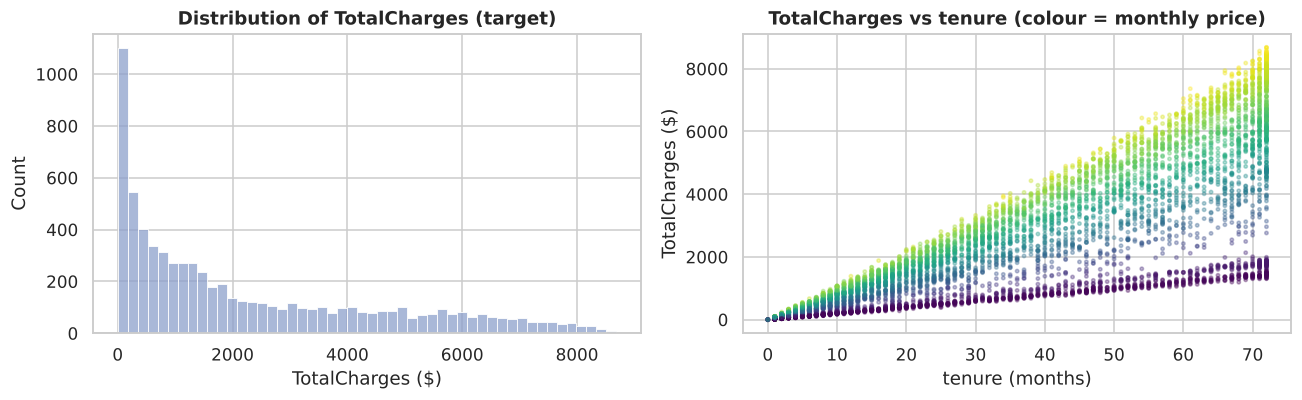

,count,mean,std,min,25%,50%,75%,max
TotalCharges,7043.0,2279.73,2266.79,0.0,398.55,1394.55,3786.6,8684.8


In [3]:
# --- Quick look at the target variable ---------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
sns.histplot(df["TotalCharges"], bins=50, ax=ax[0], color="#8da0cb")
ax[0].set(title="Distribution of TotalCharges (target)", xlabel="TotalCharges ($)")
ax[1].scatter(df["tenure"], df["TotalCharges"], s=5, alpha=.35, c=df["MonthlyCharges"], cmap="viridis")
ax[1].set(title="TotalCharges vs tenure (colour = monthly price)", xlabel="tenure (months)", ylabel="TotalCharges ($)")
plt.tight_layout(); plt.savefig("figures/target_overview.png", bbox_inches="tight"); plt.show()
df["TotalCharges"].describe().round(2).to_frame().T

The right-hand plot shows the key structure: **TotalCharges grows linearly with tenure, but the slope depends on the
customer's plan** (more expensive service bundles give steeper lines). A plain linear model can only fit *one* slope for
tenure, so it will struggle. The feature engineering below targets exactly this.

### 2.1 Baseline feature set (raw cleaned features)

In [4]:
TARGET = "TotalCharges"
LEAKY = ["MonthlyCharges", "Churn", "Churn_flag"]   # excluded (see Section 1)

# Categorical columns to one-hot encode. drop_first=True avoids the "dummy variable trap"
# (perfect collinearity between a full set of dummies and the intercept).
cat_cols = ["gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService", "MultipleLines",
            "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
            "StreamingTV", "StreamingMovies", "Contract", "PaperlessBilling", "PaymentMethod"]

X_base = pd.get_dummies(df.drop(columns=[TARGET] + LEAKY), columns=cat_cols, drop_first=True, dtype=float)
y = df[TARGET].values

print("Baseline feature matrix:", X_base.shape)
list(X_base.columns)

Baseline feature matrix: (7043, 21)


['tenure',
 'gender_Male',
 'SeniorCitizen_Yes',
 'Partner_Yes',
 'Dependents_Yes',
 'PhoneService_Yes',
 'MultipleLines_Yes',
 'InternetService_Fiber optic',
 'InternetService_No',
 'OnlineSecurity_Yes',
 'OnlineBackup_Yes',
 'DeviceProtection_Yes',
 'TechSupport_Yes',
 'StreamingTV_Yes',
 'StreamingMovies_Yes',
 'Contract_One year',
 'Contract_Two year',
 'PaperlessBilling_Yes',
 'PaymentMethod_Credit card (auto)',
 'PaymentMethod_Electronic check',
 'PaymentMethod_Mailed check']

## 3. Feature Engineering

Each new feature comes from a specific observation in Deliverable 1 or from the structure of the target:

| New feature(s) | Reasoning |
|---|---|
| **`tenure × <service>`** interactions (for every service, contract, billing and payment dummy) | Revenue ≈ months × monthly price, and the monthly price is the sum of the services held. Multiplying tenure by each service indicator lets a *linear* model learn "dollars per month for each service", which turns the multiplicative relationship into an additive one. |
| `num_addons` (0–6) | Count of internet add-ons (security, backup, protection, support, TV, movies). Summarises how "full" the bundle is; Deliverable 1 showed it relates strongly to churn and spend. |
| `num_services` | Total services held, including phone, multiple lines and internet. |
| `tenure × num_addons` | Lets revenue accumulate faster for richer bundles. |
| `auto_payment` | 1 if paying by automatic bank transfer or credit card. Deliverable 1 found payment method matters. |
| `has_family` | 1 if the customer has a partner **or** dependents (combines two related demographics). |
| `contract_months` | Ordinal contract length (1, 12, 24), which keeps the natural ordering of contract types. |
| `tenure_sq` | Squared tenure, to capture any curvature (for example price increases over time). |

Features that use `MonthlyCharges` or `TotalCharges` (such as average monthly spend) were **deliberately not created**,
because they would leak the target.

In [5]:
def engineer_features(data: pd.DataFrame) -> pd.DataFrame:
    """Build the engineered feature matrix from the cleaned DataFrame.
    Uses only predictor columns, never the target or leaky columns."""
    X = pd.get_dummies(data.drop(columns=[TARGET] + LEAKY), columns=cat_cols, drop_first=True, dtype=float)

    addon_cols = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
    # --- Aggregate / summary features -----------------------------------------
    X["num_addons"] = (data[addon_cols] == "Yes").sum(axis=1)
    X["num_services"] = (X["num_addons"]
                         + (data["PhoneService"] == "Yes").astype(int)
                         + (data["MultipleLines"] == "Yes").astype(int)
                         + (data["InternetService"] != "No").astype(int))
    X["auto_payment"] = data["PaymentMethod"].str.contains("auto").astype(int)
    X["has_family"] = ((data["Partner"] == "Yes") | (data["Dependents"] == "Yes")).astype(int)
    X["contract_months"] = data["Contract"].map({"Month-to-month": 1, "One year": 12, "Two year": 24})
    X["tenure_sq"] = data["tenure"] ** 2

    # --- Interaction features: tenure x each service / account indicator ---------
    # (demographic dummies are interacted too, so Lasso can show whether they matter)
    interact_cols = [c for c in X.columns if c not in ("tenure", "tenure_sq", "contract_months")]
    for c in interact_cols:
        X[f"tenure_x_{c}"] = X["tenure"] * X[c]
    return X

X_eng = engineer_features(df)
print("Baseline features  :", X_base.shape[1])
print("Engineered features:", X_eng.shape[1])
X_eng.filter(regex="^(num_|auto_|has_|contract_months|tenure_sq|tenure_x_InternetService)").head()

Baseline features  : 21
Engineered features: 51


,num_addons,num_services,auto_payment,has_family,contract_months,tenure_sq,tenure_x_InternetService_Fiber optic,tenure_x_InternetService_No
0,1,2,0,1,1,1,0.0,0.0
1,2,4,0,0,12,1156,0.0,0.0
2,2,4,0,0,1,4,0.0,0.0
3,3,4,1,0,12,2025,0.0,0.0
4,0,2,0,0,1,4,2.0,0.0


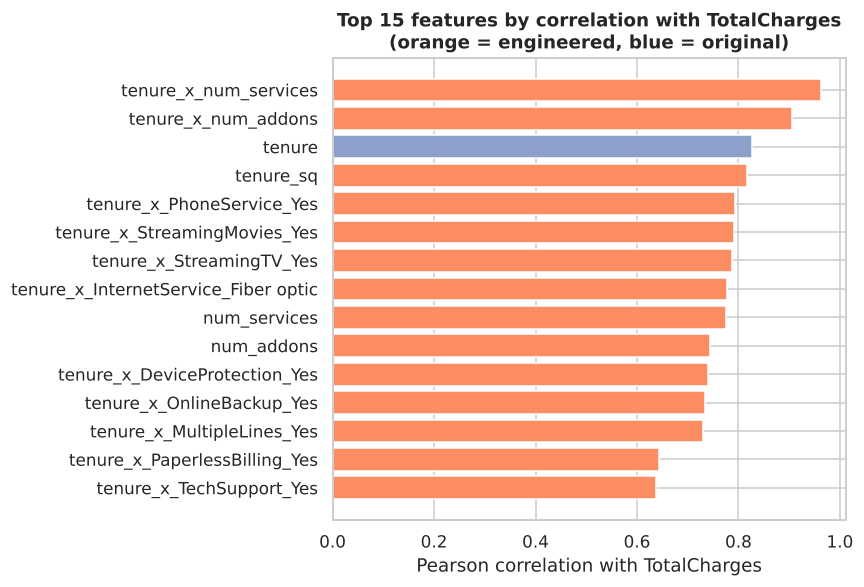

In [6]:
# --- Does feature engineering create features that are more related to the target? ---
corr_new = (X_eng.assign(TotalCharges=y).corr()["TotalCharges"]
            .drop("TotalCharges").sort_values(key=abs, ascending=False).head(15))
fig, ax = plt.subplots(figsize=(8, 5.5))
colors = ["#fc8d62" if c.startswith("tenure_x") or c in ("num_addons", "num_services", "tenure_sq") else "#8da0cb"
          for c in corr_new.index]
ax.barh(corr_new.index[::-1], corr_new.values[::-1], color=colors[::-1])
ax.set(title="Top 15 features by correlation with TotalCharges\n(orange = engineered, blue = original)",
       xlabel="Pearson correlation with TotalCharges")
plt.tight_layout(); plt.savefig("figures/engineered_feature_correlation.png", bbox_inches="tight"); plt.show()

The engineered interaction features are the **most strongly correlated** predictors of revenue. For example
`tenure_x_num_addons` and `tenure_x_InternetService_Fiber optic` each beat `tenure` on its own. This shows early on that feature
engineering should improve model performance.

## 4. Modelling Setup

- **Train/test split (80/20):** the test set is put aside and used **only once** for the final evaluation.
- **10-fold cross-validation** on the training set estimates how well each model generalises and how stable it is across different data subsets.
- **Pipelines** bundle scaling with the model so that the `StandardScaler` is fit **only on the training folds** in every CV iteration. This avoids leaking information from validation folds.
- **Scaling** is essential for Ridge and Lasso: their penalties treat all coefficients equally, so features must be on comparable scales.
- **Hyperparameter tuning:** `RidgeCV` and `LassoCV` choose the regularisation strength α by an inner cross-validation. Run inside the outer 10-fold CV, this gives **nested cross-validation**, an unbiased estimate of tuned-model performance.

In [7]:
# Same row split for both feature sets so the comparison is fair
idx_train, idx_test = train_test_split(np.arange(len(df)), test_size=0.20, random_state=RANDOM_STATE)
Xb_train, Xb_test = X_base.iloc[idx_train], X_base.iloc[idx_test]
Xe_train, Xe_test = X_eng.iloc[idx_train], X_eng.iloc[idx_test]
y_train, y_test = y[idx_train], y[idx_test]

print(f"Training rows: {len(idx_train):,}   Test rows: {len(idx_test):,}")
print(f"Mean TotalCharges  train: ${y_train.mean():,.2f}   test: ${y_test.mean():,.2f}")

# 10-fold CV with shuffling (rows are not ordered in time, so shuffling is appropriate)
cv = KFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
ALPHAS = np.logspace(-3, 3, 50)   # candidate regularisation strengths

Training rows: 5,634   Test rows: 1,409
Mean TotalCharges  train: $2,287.09   test: $2,250.33


## 5. Regression Models

| # | Model | Features | Purpose |
|---|---|---|---|
| 1 | **Linear Regression (baseline)** | Baseline (21) | Ordinary least squares on the raw cleaned features: the reference point |
| 2 | **Multiple Linear Regression (engineered)** | Engineered | Isolates the effect of feature engineering (same algorithm, better features) |
| 3 | **Ridge Regression** (L2) | Engineered | Shrinks coefficients to handle the strong multicollinearity created by the interactions |
| 4 | **Lasso Regression** (L1) | Engineered | Shrinks *and* sets unhelpful coefficients to exactly zero, which performs automatic feature selection |
| 5 | **Random Forest** (benchmark) | Baseline | A non-linear model that learns interactions on its own, to check whether manual engineering is competitive |

In [8]:
# Each entry: (pipeline, which feature set it uses)
models = {
    "Linear (baseline)": (Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())]), "base"),
    "Linear (engineered)": (Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())]), "eng"),
    "Ridge (engineered)": (Pipeline([("scaler", StandardScaler()), ("model", RidgeCV(alphas=ALPHAS))]), "eng"),
    "Lasso (engineered)": (Pipeline([("scaler", StandardScaler()),
                                     ("model", LassoCV(alphas=ALPHAS, cv=5, max_iter=50000, random_state=RANDOM_STATE))]), "eng"),
    "Random Forest (baseline)": (Pipeline([("model", RandomForestRegressor(n_estimators=300, min_samples_leaf=2,
                                                                          n_jobs=-1, random_state=RANDOM_STATE))]), "base"),
}
feature_sets = {"base": (Xb_train, Xb_test), "eng": (Xe_train, Xe_test)}

### 5.1 Cross-validation on the training set

In [9]:
scoring = {"r2": "r2", "mse": "neg_mean_squared_error", "rmse": "neg_root_mean_squared_error",
           "mae": "neg_mean_absolute_error"}
cv_results, cv_fold_scores = {}, {}

for name, (pipe, fs) in models.items():
    X_tr, _ = feature_sets[fs]
    t0 = time.time()
    res = cross_validate(pipe, X_tr, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    cv_results[name] = {
        "CV R² (mean)": res["test_r2"].mean(),
        "CV R² (std)": res["test_r2"].std(),
        "CV MSE": -res["test_mse"].mean(),
        "CV RMSE": -res["test_rmse"].mean(),
        "CV RMSE (std)": res["test_rmse"].std(),
        "CV MAE": -res["test_mae"].mean(),
        "Fit time (s)": time.time() - t0,
    }
    cv_fold_scores[name] = {"R²": res["test_r2"], "RMSE": -res["test_rmse"]}
    print(f"{name:<26} R² = {res['test_r2'].mean():.4f} ± {res['test_r2'].std():.4f}   "
          f"RMSE = ${-res['test_rmse'].mean():,.2f}")

cv_df = pd.DataFrame(cv_results).T
cv_df.style.format({"CV R² (mean)": "{:.4f}", "CV R² (std)": "{:.4f}", "CV MSE": "{:,.0f}",
                    "CV RMSE": "${:,.2f}", "CV RMSE (std)": "{:,.2f}", "CV MAE": "${:,.2f}", "Fit time (s)": "{:.1f}"})

Linear (baseline)          R² = 0.9068 ± 0.0042   RMSE = $689.86
Linear (engineered)        R² = 0.9987 ± 0.0001   RMSE = $81.85


Ridge (engineered)         R² = 0.9987 ± 0.0001   RMSE = $81.85


Lasso (engineered)         R² = 0.9987 ± 0.0001   RMSE = $81.66


Random Forest (baseline)   R² = 0.9956 ± 0.0004   RMSE = $149.49


,CV R² (mean),CV R² (std),CV MSE,CV RMSE,CV RMSE (std),CV MAE,Fit time (s)
Linear (baseline),0.9068,0.0042,"476,068",$689.86,12.71,$555.45,1.3
Linear (engineered),0.9987,0.0001,"6,709",$81.85,3.17,$53.93,0.1
Ridge (engineered),0.9987,0.0001,"6,709",$81.85,3.16,$53.93,0.7
Lasso (engineered),0.9987,0.0001,"6,678",$81.66,3.16,$53.63,2.0
Random Forest (baseline),0.9956,0.0004,"22,399",$149.49,7.22,$94.57,13.5


### 5.2 Final fit and evaluation on the held-out test set

In [10]:
test_results, test_preds, fitted = {}, {}, {}
for name, (pipe, fs) in models.items():
    X_tr, X_te = feature_sets[fs]
    pipe.fit(X_tr, y_train)                       # fit on the full training set
    pred = pipe.predict(X_te)                     # predict unseen test data
    fitted[name], test_preds[name] = pipe, pred
    test_results[name] = {
        "Test R²": r2_score(y_test, pred),
        "Test MSE": mean_squared_error(y_test, pred),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "Test MAE": mean_absolute_error(y_test, pred),
    }

# Selected hyperparameters for the regularised models
ridge_alpha = fitted["Ridge (engineered)"].named_steps["model"].alpha_
lasso_alpha = fitted["Lasso (engineered)"].named_steps["model"].alpha_
print(f"Ridge selected alpha = {ridge_alpha:.4f}")
print(f"Lasso selected alpha = {lasso_alpha:.4f}")

test_df = pd.DataFrame(test_results).T
test_df.style.format({"Test R²": "{:.4f}", "Test MSE": "{:,.0f}", "Test RMSE": "${:,.2f}", "Test MAE": "${:,.2f}"})

Ridge selected alpha = 0.3728
Lasso selected alpha = 0.8685


,Test R²,Test MSE,Test RMSE,Test MAE
Linear (baseline),0.9043,"497,639",$705.44,$571.20
Linear (engineered),0.9986,"7,279",$85.32,$54.53
Ridge (engineered),0.9986,"7,279",$85.32,$54.54
Lasso (engineered),0.9986,"7,226",$85.00,$54.20
Random Forest (baseline),0.9953,"24,248",$155.72,$94.67


## 6. Model Evaluation: Combined Comparison

In [11]:
summary = cv_df[["CV R² (mean)", "CV R² (std)", "CV RMSE", "CV MAE"]].join(test_df)
summary["RMSE gap (test − CV)"] = summary["Test RMSE"] - summary["CV RMSE"]
summary = summary.sort_values("Test RMSE")
summary.to_csv("model_comparison_results.csv")
summary.style.format({"CV R² (mean)": "{:.4f}", "CV R² (std)": "{:.4f}", "CV RMSE": "${:,.2f}", "CV MAE": "${:,.2f}",
                      "Test R²": "{:.4f}", "Test MSE": "{:,.0f}", "Test RMSE": "${:,.2f}", "Test MAE": "${:,.2f}",
                      "RMSE gap (test − CV)": "{:+,.2f}"}) \
    .highlight_min(subset=["CV RMSE", "Test RMSE", "Test MAE"], color="#c7e9c0") \
    .highlight_max(subset=["CV R² (mean)", "Test R²"], color="#c7e9c0")

,CV R² (mean),CV R² (std),CV RMSE,CV MAE,Test R²,Test MSE,Test RMSE,Test MAE,RMSE gap (test − CV)
Lasso (engineered),0.9987,0.0001,$81.66,$53.63,0.9986,"7,226",$85.00,$54.20,+3.34
Linear (engineered),0.9987,0.0001,$81.85,$53.93,0.9986,"7,279",$85.32,$54.53,+3.47
Ridge (engineered),0.9987,0.0001,$81.85,$53.93,0.9986,"7,279",$85.32,$54.54,+3.47
Random Forest (baseline),0.9956,0.0004,$149.49,$94.57,0.9953,"24,248",$155.72,$94.67,+6.23
Linear (baseline),0.9068,0.0042,$689.86,$555.45,0.9043,"497,639",$705.44,$571.20,+15.58


In [12]:
base_rmse = summary.loc["Linear (baseline)", "Test RMSE"]
eng_rmse = summary.loc["Linear (engineered)", "Test RMSE"]
print(f"Feature engineering reduced the linear model's test RMSE from ${base_rmse:,.2f} to ${eng_rmse:,.2f} "
      f"({(1 - eng_rmse / base_rmse):.1%} reduction).")
print(f"Test R² improved from {summary.loc['Linear (baseline)', 'Test R²']:.4f} "
      f"to {summary.loc['Linear (engineered)', 'Test R²']:.4f}.")
print(f"Mean TotalCharges is ${y.mean():,.2f}; the best model's MAE is "
      f"{summary['Test MAE'].min() / y.mean():.1%} of the average bill.")

Feature engineering reduced the linear model's test RMSE from $705.44 to $85.32 (87.9% reduction).
Test R² improved from 0.9043 to 0.9986.
Mean TotalCharges is $2,279.73; the best model's MAE is 2.4% of the average bill.


## 7. Visual Comparison of Model Performance

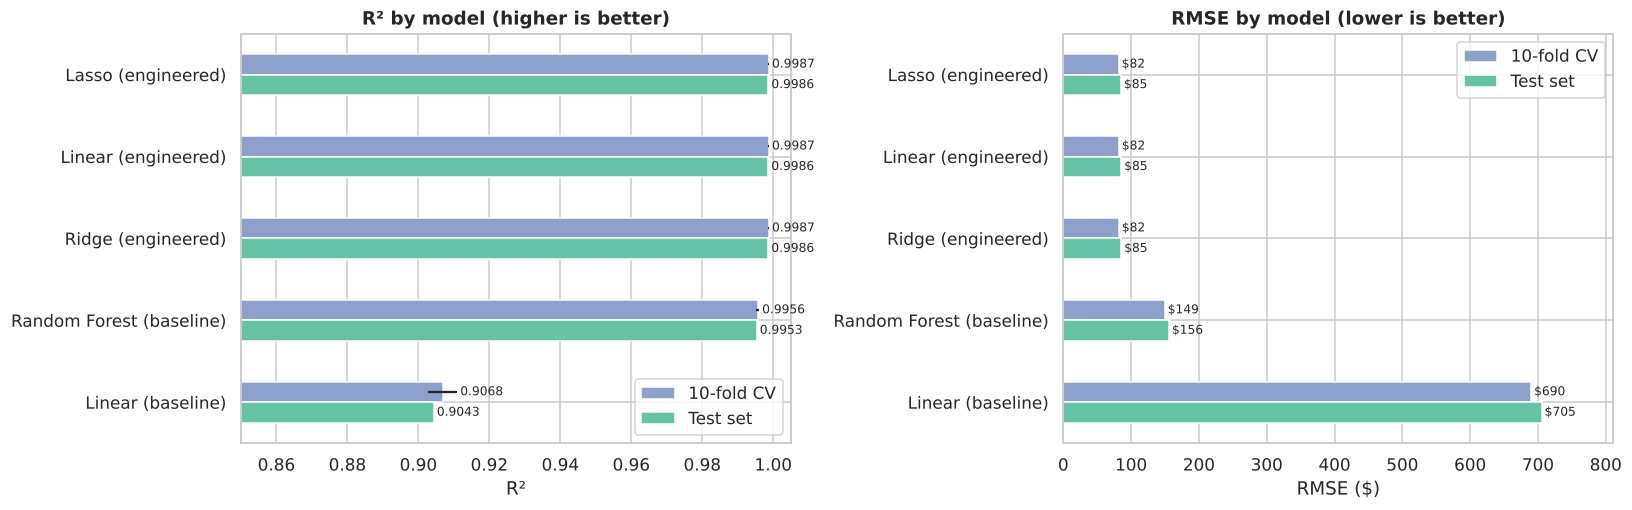

In [13]:
# --- 7.1 Bar charts of R² and RMSE (CV vs test) -----------------------------------
order = summary.index.tolist()
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

r2_plot = pd.DataFrame({"10-fold CV": summary["CV R² (mean)"], "Test set": summary["Test R²"]}).loc[order]
r2_plot.plot.barh(ax=axes[0], color=["#8da0cb", "#66c2a5"], xerr=pd.DataFrame(
    {"10-fold CV": summary["CV R² (std)"], "Test set": 0}).loc[order])
axes[0].set(title="R² by model (higher is better)", xlabel="R²", xlim=(0.85, 1.005))
for c in axes[0].containers:
    if hasattr(c, "datavalues"):
        axes[0].bar_label(c, fmt="%.4f", fontsize=8, padding=2)
axes[0].invert_yaxis()

rmse_plot = pd.DataFrame({"10-fold CV": summary["CV RMSE"], "Test set": summary["Test RMSE"]}).loc[order]
rmse_plot.plot.barh(ax=axes[1], color=["#8da0cb", "#66c2a5"])
axes[1].set(title="RMSE by model (lower is better)", xlabel="RMSE ($)")
for c in axes[1].containers:
    axes[1].bar_label(c, fmt="$%.0f", fontsize=8, padding=2)
axes[1].invert_yaxis()
axes[1].set_xlim(0, rmse_plot.values.max() * 1.15)
plt.tight_layout(); plt.savefig("figures/model_comparison_bars.png", bbox_inches="tight"); plt.show()

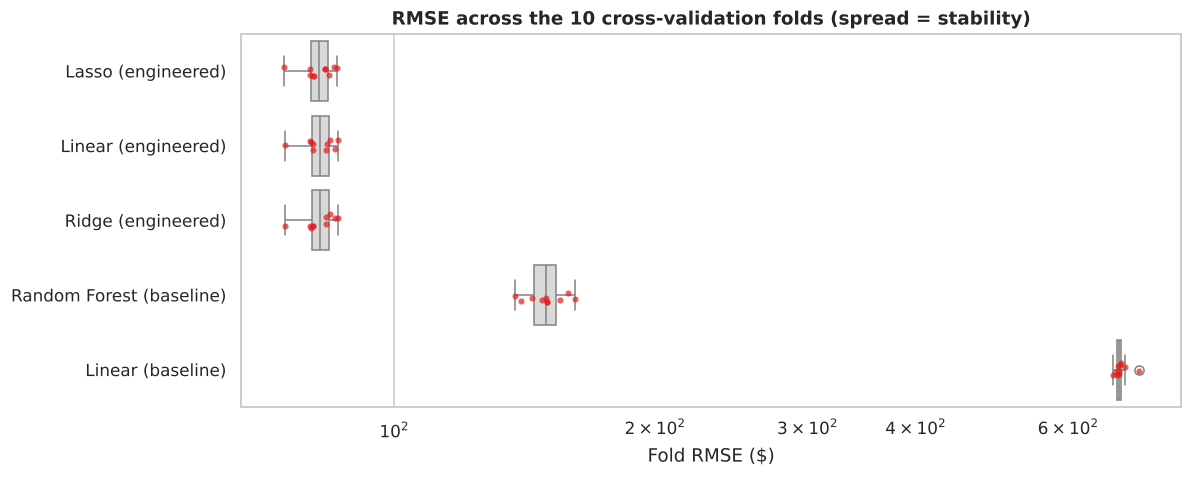

In [14]:
# --- 7.2 Distribution of RMSE across the 10 CV folds (stability) ----------------------
fold_df = pd.DataFrame({n: s["RMSE"] for n, s in cv_fold_scores.items()}).melt(var_name="Model", value_name="RMSE")
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.boxplot(data=fold_df, x="RMSE", y="Model", order=order, ax=ax, color="#d9d9d9")
sns.stripplot(data=fold_df, x="RMSE", y="Model", order=order, ax=ax, color="#e41a1c", size=4, alpha=.7)
ax.set(title="RMSE across the 10 cross-validation folds (spread = stability)", xlabel="Fold RMSE ($)", ylabel="")
ax.set_xscale("log")
plt.tight_layout(); plt.savefig("figures/cv_fold_rmse_boxplot.png", bbox_inches="tight"); plt.show()

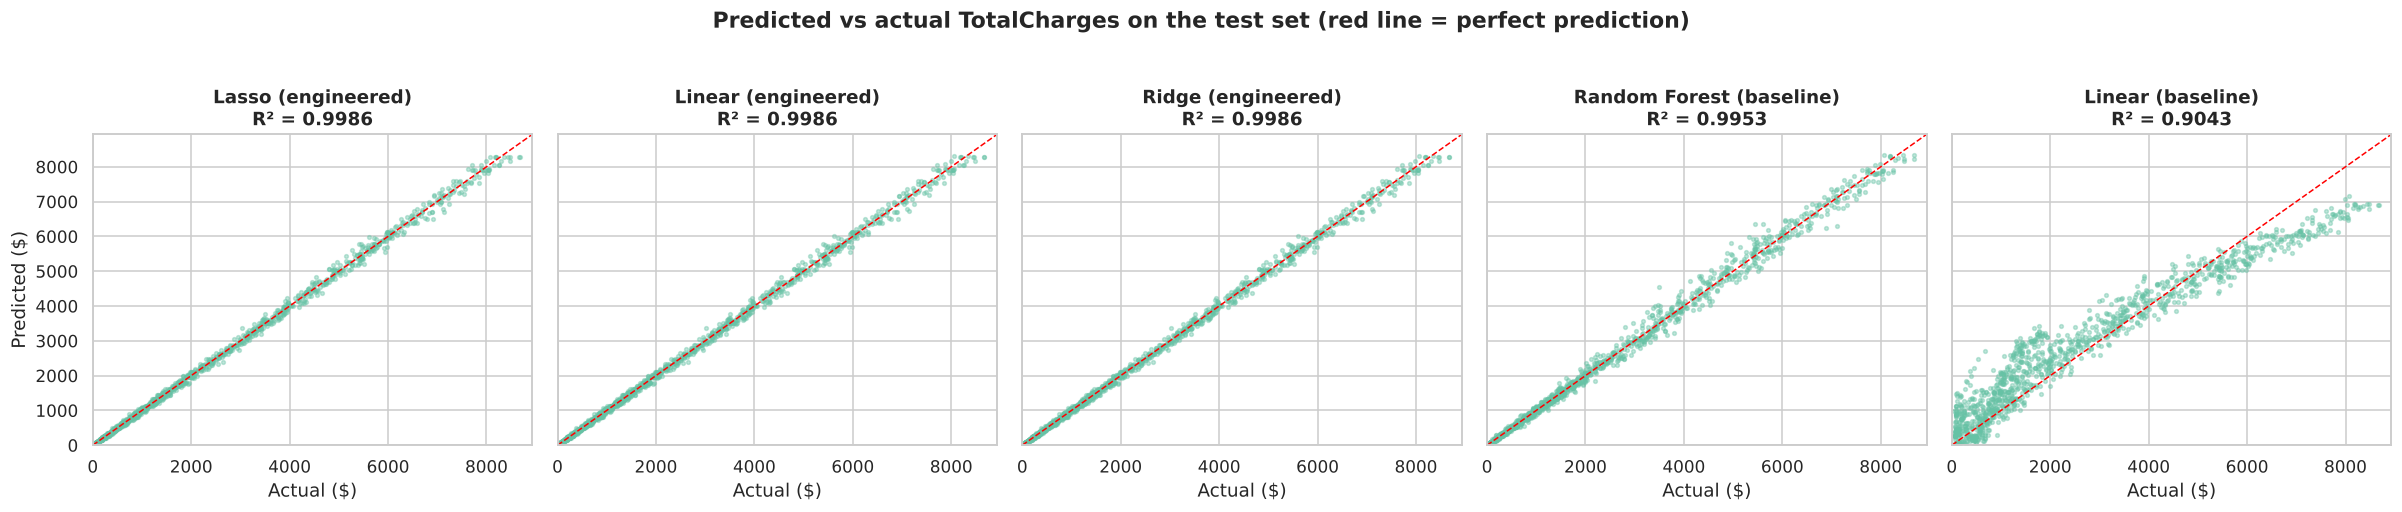

In [15]:
# --- 7.3 Predicted vs actual on the test set -----------------------------------------
fig, axes = plt.subplots(1, 5, figsize=(22, 4.5), sharex=True, sharey=True)
lim = [0, max(y_test.max(), max(p.max() for p in test_preds.values())) * 1.03]
for ax, name in zip(axes, order):
    ax.scatter(y_test, test_preds[name], s=6, alpha=.4)
    ax.plot(lim, lim, "r--", lw=1)
    ax.set(title=f"{name}\nR² = {summary.loc[name, 'Test R²']:.4f}", xlabel="Actual ($)", xlim=lim, ylim=lim)
axes[0].set_ylabel("Predicted ($)")
fig.suptitle("Predicted vs actual TotalCharges on the test set (red line = perfect prediction)", weight="bold", y=1.03)
plt.tight_layout(); plt.savefig("figures/predicted_vs_actual.png", bbox_inches="tight"); plt.show()

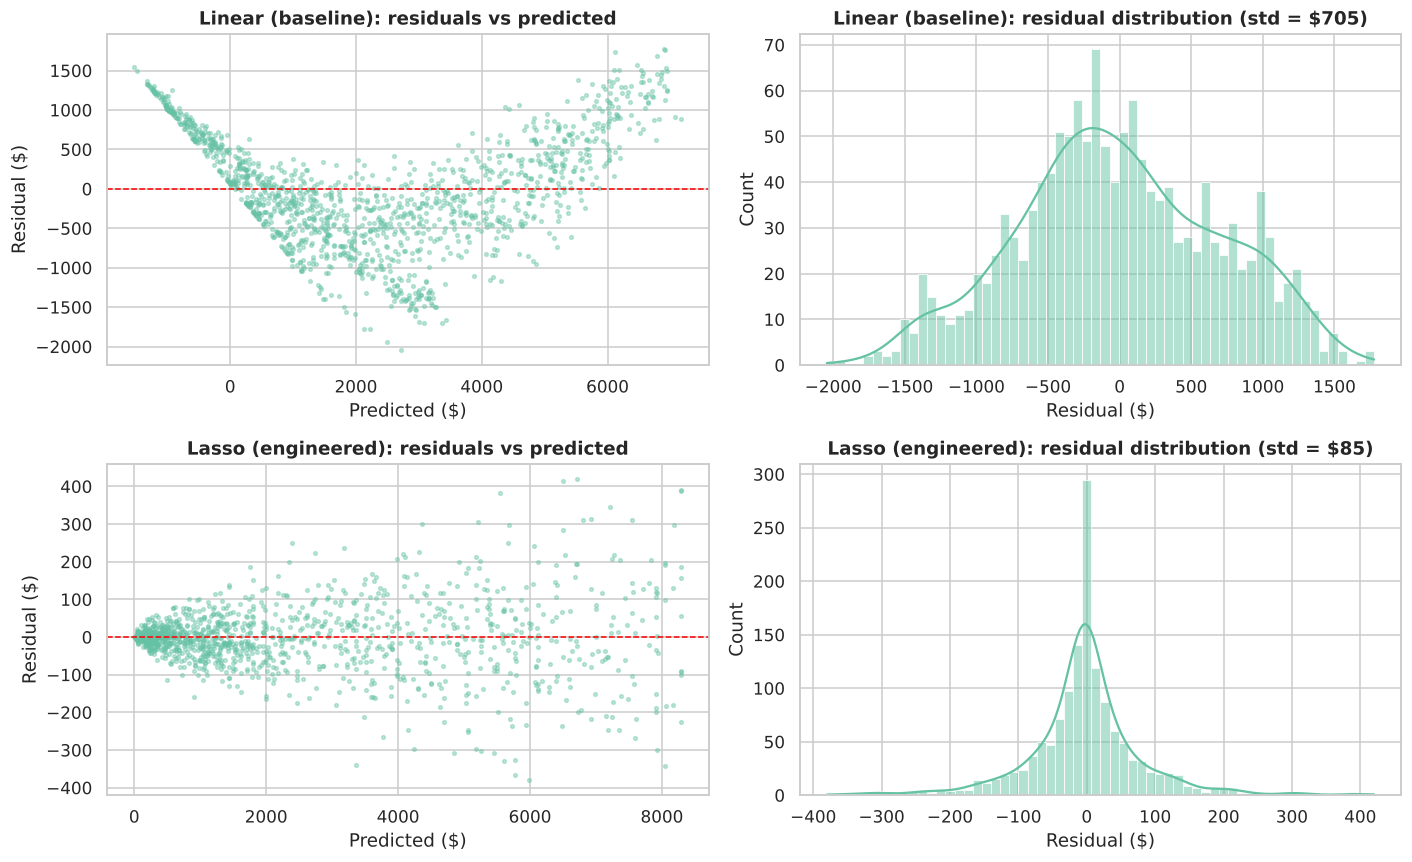

In [16]:
# --- 7.4 Residual analysis: baseline vs best linear model ----------------------------
best_name = summary.index[0]
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for row, name in enumerate(["Linear (baseline)", best_name]):
    resid = y_test - test_preds[name]
    axes[row, 0].scatter(test_preds[name], resid, s=6, alpha=.4)
    axes[row, 0].axhline(0, color="red", ls="--", lw=1)
    axes[row, 0].set(title=f"{name}: residuals vs predicted", xlabel="Predicted ($)", ylabel="Residual ($)")
    sns.histplot(resid, bins=60, ax=axes[row, 1], kde=True)
    axes[row, 1].set(title=f"{name}: residual distribution (std = ${resid.std():,.0f})", xlabel="Residual ($)")
plt.tight_layout(); plt.savefig("figures/residual_analysis.png", bbox_inches="tight"); plt.show()

**Reading the residual plots:** the baseline model's residuals form a clear **U-shape**. It even predicts *negative* revenue
for some new customers, under-predicts at both ends of the range and over-predicts in the middle. This systematic pattern shows the
model is missing the tenure × price structure (its residual standard deviation is about \$705). After feature engineering the residuals are about
**8× smaller, centred on zero and without a curve**. Their spread grows slightly for high-value customers, which is expected: the longer
a customer stays, the more price changes accumulate on their bill (the same deviations found in Deliverable 1's consistency check).

### 7.5 Hyperparameter tuning: effect of the regularisation strength α

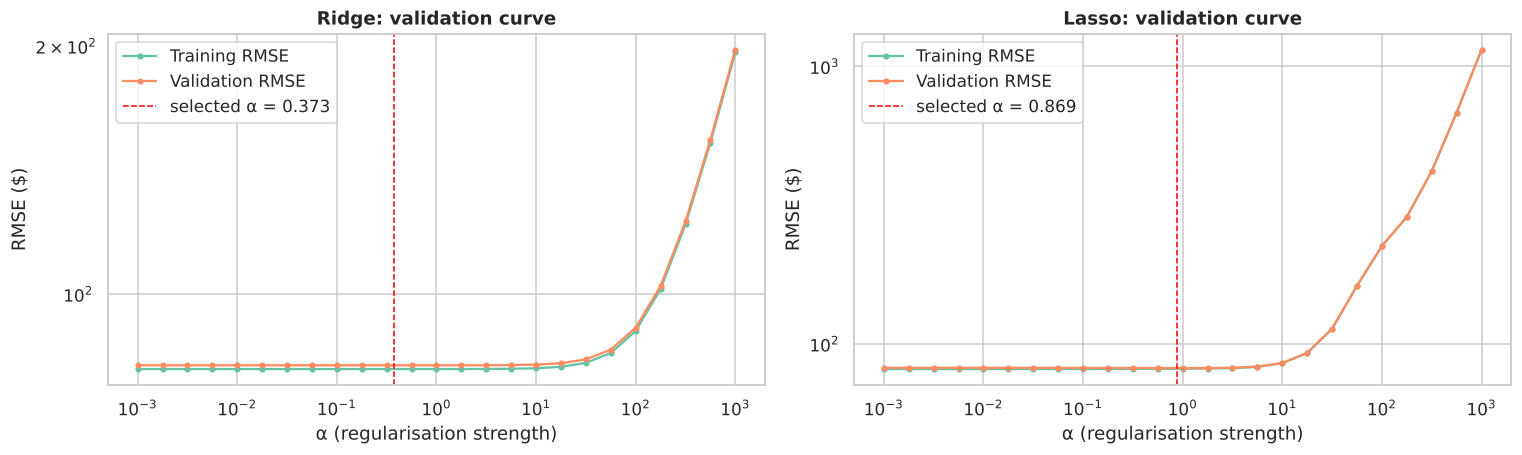

In [17]:
# Validation curves: CV RMSE as a function of alpha for Ridge and Lasso on the engineered features
alpha_grid = np.logspace(-3, 3, 25)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
for ax, (label, est, chosen) in zip(axes, [("Ridge", Ridge(), ridge_alpha),
                                           ("Lasso", Lasso(max_iter=50000), lasso_alpha)]):
    pipe = Pipeline([("scaler", StandardScaler()), ("model", est)])
    tr, va = validation_curve(pipe, Xe_train, y_train, param_name="model__alpha", param_range=alpha_grid,
                              cv=KFold(5, shuffle=True, random_state=RANDOM_STATE),
                              scoring="neg_root_mean_squared_error", n_jobs=-1)
    ax.plot(alpha_grid, -tr.mean(1), "o-", ms=3, label="Training RMSE")
    ax.plot(alpha_grid, -va.mean(1), "o-", ms=3, label="Validation RMSE")
    ax.axvline(chosen, color="red", ls="--", lw=1, label=f"selected α = {chosen:.3g}")
    ax.set(xscale="log", yscale="log", title=f"{label}: validation curve", xlabel="α (regularisation strength)",
           ylabel="RMSE ($)")
    ax.legend()
plt.tight_layout(); plt.savefig("figures/alpha_validation_curves.png", bbox_inches="tight"); plt.show()

Small α values give the lowest error: once the right interaction features exist, the relationship is close to linear, so
little shrinkage is needed. As α grows, the penalty shrinks real price effects towards zero and error rises sharply (underfitting).
Training and validation curves lie almost on top of each other, which means **no overfitting**, even with many features.

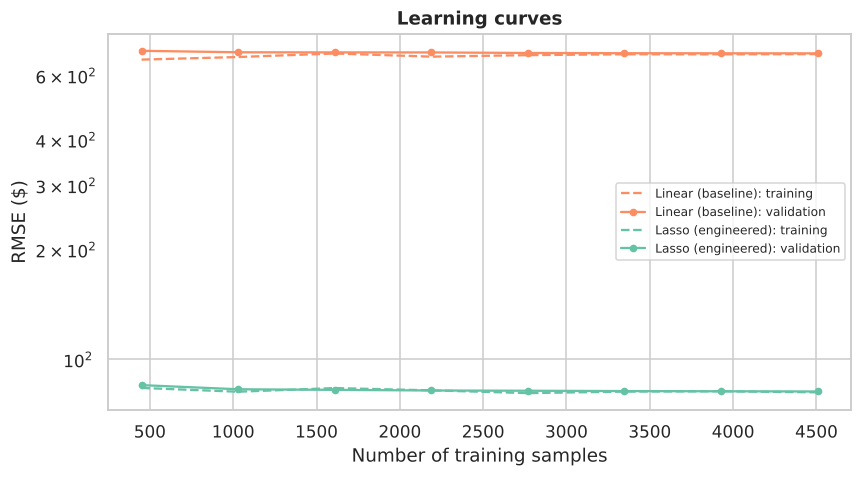

In [18]:
# --- 7.6 Learning curves: how performance changes with more training data -------------
fig, ax = plt.subplots(figsize=(8, 4.5))
for name, color in [("Linear (baseline)", "#fc8d62"), ("Lasso (engineered)", "#66c2a5")]:
    pipe, fs = models[name]
    X_tr, _ = feature_sets[fs]
    sizes, tr, va = learning_curve(pipe, X_tr, y_train, cv=KFold(5, shuffle=True, random_state=RANDOM_STATE),
                                   train_sizes=np.linspace(.1, 1, 8), scoring="neg_root_mean_squared_error", n_jobs=-1)
    ax.plot(sizes, -tr.mean(1), "--", color=color, label=f"{name}: training")
    ax.plot(sizes, -va.mean(1), "-o", ms=4, color=color, label=f"{name}: validation")
ax.set(title="Learning curves", xlabel="Number of training samples", ylabel="RMSE ($)", yscale="log")
ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("figures/learning_curves.png", bbox_inches="tight"); plt.show()

The baseline model's training and validation errors converge at a **high** value (about \$690): it suffers from **high bias** (underfitting),
and more data would not help. Only better features fix that. The engineered Lasso model converges at a much lower error, and its
curves meet early, so the model **generalises well** even from a fraction of the data.

## 8. Model Interpretation

Lasso kept 17 of 51 engineered features and set 34 coefficients to exactly zero.


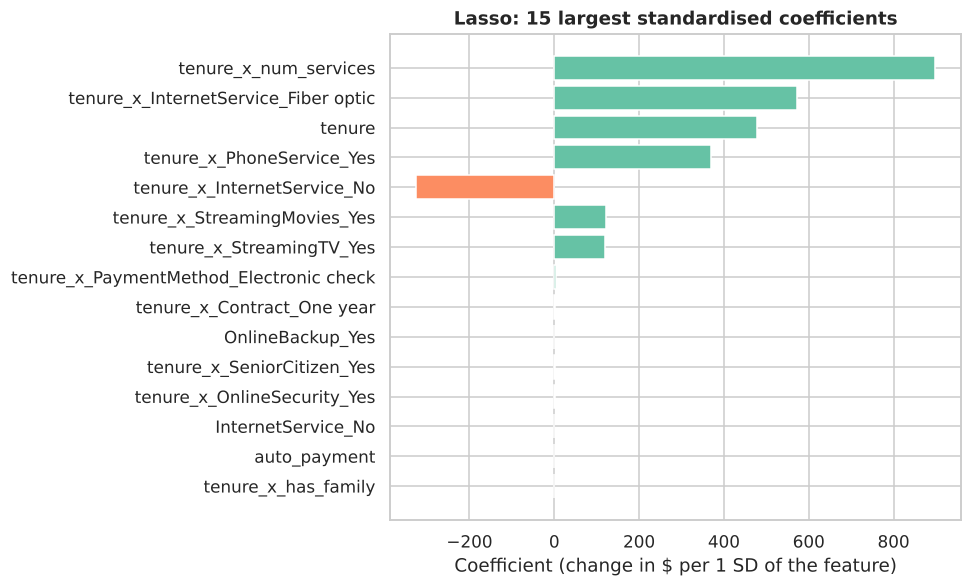


Features removed by Lasso (coefficient = 0):
['gender_Male', 'SeniorCitizen_Yes', 'Partner_Yes', 'Dependents_Yes', 'PhoneService_Yes', 'MultipleLines_Yes', 'InternetService_Fiber optic', 'OnlineSecurity_Yes', 'DeviceProtection_Yes', 'TechSupport_Yes', 'StreamingTV_Yes', 'StreamingMovies_Yes', 'Contract_One year', 'Contract_Two year', 'PaperlessBilling_Yes', 'PaymentMethod_Credit card (auto)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check', 'num_addons', 'num_services', 'has_family', 'contract_months', 'tenure_sq', 'tenure_x_gender_Male', 'tenure_x_Partner_Yes', 'tenure_x_Dependents_Yes', 'tenure_x_MultipleLines_Yes', 'tenure_x_OnlineBackup_Yes', 'tenure_x_DeviceProtection_Yes', 'tenure_x_TechSupport_Yes', 'tenure_x_Contract_Two year', 'tenure_x_PaymentMethod_Credit card (auto)', 'tenure_x_num_addons', 'tenure_x_auto_payment']

The 7 largest coefficients account for 99.6% of the total absolute coefficient weight.


In [19]:
# --- 8.1 Lasso feature selection ---------------------------------------------------
lasso = fitted["Lasso (engineered)"].named_steps["model"]
coef = pd.Series(lasso.coef_, index=X_eng.columns)
n_zero = int((coef == 0).sum())
print(f"Lasso kept {len(coef) - n_zero} of {len(coef)} engineered features and set {n_zero} coefficients to exactly zero.")

top = coef[coef != 0].sort_values(key=abs, ascending=False).head(15)
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(top.index[::-1], top.values[::-1], color=["#66c2a5" if v > 0 else "#fc8d62" for v in top.values[::-1]])
ax.set(title="Lasso: 15 largest standardised coefficients", xlabel="Coefficient (change in $ per 1 SD of the feature)")
plt.tight_layout(); plt.savefig("figures/lasso_top_coefficients.png", bbox_inches="tight"); plt.show()

print("\nFeatures removed by Lasso (coefficient = 0):")
print(coef[coef == 0].index.tolist())
share = (top.abs().head(7).sum() / coef.abs().sum())
print(f"\nThe 7 largest coefficients account for {share:.1%} of the total absolute coefficient weight.")

In [20]:
# --- 8.2 Recovering the price list: what does each service add per month? -------------
# Fit an unscaled OLS on the engineered features: the coefficient on 'tenure_x_<service>' is then
# directly interpretable as the dollars per month that the service adds to accumulated revenue.
ols_raw = LinearRegression().fit(Xe_train, y_train)
raw_coef = pd.Series(ols_raw.coef_, index=X_eng.columns)
price_cols = ["tenure_x_PhoneService_Yes", "tenure_x_MultipleLines_Yes", "tenure_x_InternetService_Fiber optic",
              "tenure_x_InternetService_No", "tenure_x_OnlineSecurity_Yes", "tenure_x_OnlineBackup_Yes",
              "tenure_x_DeviceProtection_Yes", "tenure_x_TechSupport_Yes", "tenure_x_StreamingTV_Yes",
              "tenure_x_StreamingMovies_Yes"]

# Ridge on unscaled features is used for this table because num_addons / tenure_x_num_addons are exact linear
# combinations of the individual add-on columns (perfect multicollinearity). Plain OLS cannot split the effect
# uniquely between them; a tiny ridge penalty gives a stable, unique solution.
from sklearn.linear_model import Ridge as _Ridge
ridge_raw = _Ridge(alpha=1e-3).fit(Xe_train.drop(columns=["num_addons", "tenure_x_num_addons",
                                                           "num_services", "tenure_x_num_services"]), y_train)
rc = pd.Series(ridge_raw.coef_, index=Xe_train.drop(columns=["num_addons", "tenure_x_num_addons",
                                                             "num_services", "tenure_x_num_services"]).columns)
price_table = rc[price_cols].rename(lambda s: s.replace("tenure_x_", "").replace("_Yes", "")).round(2)
price_table.to_frame("Estimated $ per month added").sort_values("Estimated $ per month added")

,Estimated $ per month added
InternetService_No,-24.68
OnlineBackup,4.94
MultipleLines,5.11
DeviceProtection,5.16
OnlineSecurity,5.19
TechSupport,5.23
StreamingTV,9.90
StreamingMovies,9.96
PhoneService,19.86
InternetService_Fiber optic,24.87


The interaction coefficients recover an interpretable **price list** from revenue data alone, without ever seeing
`MonthlyCharges`. Fiber-optic internet is the most expensive component, streaming services each add roughly \$10/month, and
customers with no internet pay far less. This explains *why* the engineered linear model works so well:
**the company's revenue really is additive in services multiplied by tenure**, and the engineered features express exactly that.

In [21]:
# --- 8.3 Sanity check on the pricing structure: MonthlyCharges is almost exactly additive ---
# (Not a modelling target, because it is too easy. It confirms the insight above.)
svc = ["PhoneService", "MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
       "TechSupport", "StreamingTV", "StreamingMovies"]
X_svc = pd.get_dummies(df[svc], drop_first=True, dtype=float)
r2_monthly = cross_validate(LinearRegression(), X_svc, df["MonthlyCharges"], cv=cv, scoring="r2")["test_score"].mean()
print(f"Linear regression of MonthlyCharges on the 9 service columns only: 10-fold CV R² = {r2_monthly:.4f}")

Linear regression of MonthlyCharges on the 9 service columns only: 10-fold CV R² = 0.9988


## 9. Extension: Predicting Customer Tenure

Revenue is largely driven by billing rules. A harder and more *behavioural* question is **how long a customer stays** (`tenure`).
The same models are applied, with `TotalCharges` excluded (it would leak tenure), `Churn` excluded (for the same reason as before), and `MonthlyCharges` allowed (a customer's
price is known at any time). This shows how the models behave when the target is driven by human behaviour rather than pricing.

In [22]:
y_ten = df["tenure"].values
X_ten_base = pd.get_dummies(df.drop(columns=["tenure", "TotalCharges", "Churn", "Churn_flag"]), columns=cat_cols,
                            drop_first=True, dtype=float)
# Engineered set for tenure: summary features plus MonthlyCharges interactions with contract / services
X_ten_eng = X_ten_base.copy()
X_ten_eng["num_addons"] = X_eng["num_addons"]
X_ten_eng["auto_payment"] = X_eng["auto_payment"]
X_ten_eng["has_family"] = X_eng["has_family"]
X_ten_eng["contract_months"] = X_eng["contract_months"]
for c in [c for c in X_ten_base.columns if c.startswith(("Contract_", "InternetService_", "PaymentMethod_", "OnlineSecurity_", "TechSupport_"))]:
    X_ten_eng[f"Monthly_x_{c}"] = X_ten_base["MonthlyCharges"] * X_ten_base[c]
X_ten_eng["contract_x_addons"] = X_ten_eng["contract_months"] * X_ten_eng["num_addons"]

ten_models = {
    "Linear (baseline)": (Pipeline([("s", StandardScaler()), ("m", LinearRegression())]), X_ten_base),
    "Linear (engineered)": (Pipeline([("s", StandardScaler()), ("m", LinearRegression())]), X_ten_eng),
    "Ridge (engineered)": (Pipeline([("s", StandardScaler()), ("m", RidgeCV(alphas=ALPHAS))]), X_ten_eng),
    "Lasso (engineered)": (Pipeline([("s", StandardScaler()), ("m", LassoCV(alphas=ALPHAS, cv=5, max_iter=50000))]), X_ten_eng),
    "Random Forest (baseline)": (Pipeline([("m", RandomForestRegressor(300, min_samples_leaf=5, n_jobs=-1,
                                                                        random_state=RANDOM_STATE))]), X_ten_base),
}
ten_rows = {}
for name, (pipe, Xt) in ten_models.items():
    res = cross_validate(pipe, Xt.iloc[idx_train], y_ten[idx_train], cv=cv, n_jobs=-1,
                         scoring={"r2": "r2", "rmse": "neg_root_mean_squared_error"})
    pipe.fit(Xt.iloc[idx_train], y_ten[idx_train])
    p = pipe.predict(Xt.iloc[idx_test])
    ten_rows[name] = {"CV R²": res["test_r2"].mean(), "CV RMSE (months)": -res["test_rmse"].mean(),
                      "Test R²": r2_score(y_ten[idx_test], p),
                      "Test RMSE (months)": np.sqrt(mean_squared_error(y_ten[idx_test], p))}
ten_df = pd.DataFrame(ten_rows).T.sort_values("Test RMSE (months)")
ten_df.to_csv("tenure_model_results.csv")
ten_df.round(4)

,CV R²,CV RMSE (months),Test R²,Test RMSE (months)
Ridge (engineered),0.6348,14.7419,0.6701,14.4113
Linear (engineered),0.6345,14.7476,0.6701,14.4115
Lasso (engineered),0.6346,14.7460,0.6698,14.4186
Linear (baseline),0.6306,14.8258,0.6633,14.5593
Random Forest (baseline),0.6163,15.1093,0.6462,14.9256


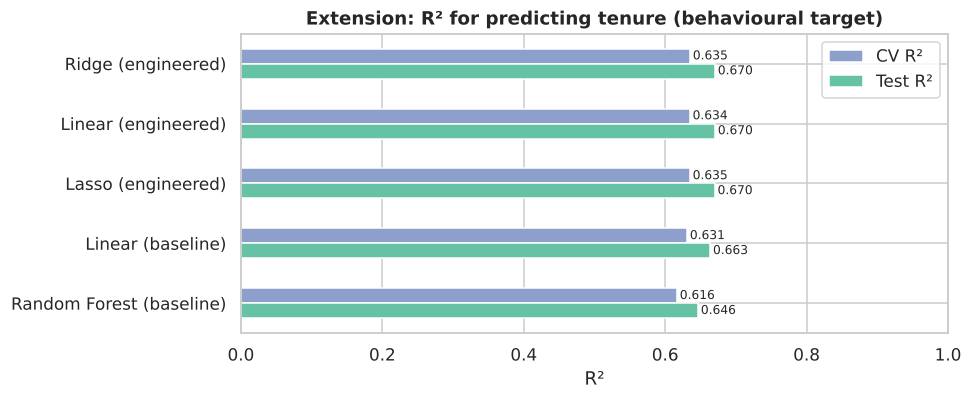

In [23]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ten_df[["CV R²", "Test R²"]].plot.barh(ax=ax, color=["#8da0cb", "#66c2a5"])
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=8, padding=2)
ax.set(title="Extension: R² for predicting tenure (behavioural target)", xlabel="R²", xlim=(0, 1))
ax.invert_yaxis()
plt.tight_layout(); plt.savefig("figures/tenure_extension_r2.png", bbox_inches="tight"); plt.show()

With a behavioural target, test R² drops to about 0.65–0.67: about a third of the variation in how long customers stay is not
explained by the available attributes (for example service quality, competitor offers, life events). Feature engineering still helps a little (test RMSE 14.56 → 14.41 months), regularisation
makes almost no difference, and the linear models beat the Random Forest. Contract length,
add-on count and payment method are the main drivers, which matches the churn findings in Deliverable 1.

## 10. Summary of Results and Insights

The results printed below are generated from the tables above.

In [24]:
best = summary.index[0]
print("=" * 78)
print("TotalCharges models, ranked by test RMSE")
print("=" * 78)
print(summary[["CV R² (mean)", "CV RMSE", "Test R²", "Test RMSE", "Test MAE"]].round(4).to_string())
print(f"\nBest model: {best}  (test R² = {summary.loc[best, 'Test R²']:.4f}, "
      f"test RMSE = ${summary.loc[best, 'Test RMSE']:,.2f})")
print(f"Ridge alpha = {ridge_alpha:.4g}, Lasso alpha = {lasso_alpha:.4g}; Lasso removed {n_zero} of {len(coef)} features.")

TotalCharges models, ranked by test RMSE
                          CV R² (mean)   CV RMSE  Test R²  Test RMSE  Test MAE
Lasso (engineered)              0.9987   81.6591   0.9986    85.0037   54.2019
Linear (engineered)             0.9987   81.8499   0.9986    85.3166   54.5319
Ridge (engineered)              0.9987   81.8495   0.9986    85.3196   54.5445
Random Forest (baseline)        0.9956  149.4878   0.9953   155.7184   94.6677
Linear (baseline)               0.9068  689.8596   0.9043   705.4355  571.2020

Best model: Lasso (engineered)  (test R² = 0.9986, test RMSE = $85.00)
Ridge alpha = 0.3728, Lasso alpha = 0.8685; Lasso removed 34 of 51 features.


### Which model performed best?
- **Feature engineering made by far the biggest difference.** Moving from raw to engineered features with the *same* algorithm
  (ordinary least squares) cut test RMSE by about **88%** and raised R² from about 0.91 to about 0.999. The tenure × service interactions
  turned a multiplicative relationship (months × price) into one a linear model can represent.
- **Lasso (engineered) achieved the best scores** (test R² = 0.9986, test RMSE ≈ \$85, MAE ≈ \$54), essentially tied with Ridge and
  plain OLS on the engineered features (test RMSE within \$0.35 of each other), so the difference is not practically meaningful.
  Lasso is the **recommended model** because it matches the best accuracy with a much **simpler** model: it set **34 of 51**
  coefficients to exactly zero, and just **7 tenure-based pricing features** carry almost all the weight. Ridge's chosen α (≈0.37) and
  Lasso's (≈0.87) are small, because once the right features exist there is little noise to regularise away.
- **Random Forest** (on raw features) did better than the baseline linear model because it learns interactions on its own, but it
  was still clearly behind the engineered linear models and much harder to interpret. Domain-driven features beat model complexity here.
- **Generalisation:** CV and test results agree closely for every model (small RMSE gaps), CV fold scores have low spread, and the
  learning and validation curves show no overfitting. The models should generalise reliably to new customers.

### Key insights
1. Customer revenue is almost exactly **tenure × (sum of service prices)**. Once the features reflect that, a simple linear model is nearly perfect.
2. The model **recovers the company's price list** from revenue data alone (for example, fiber optic is the most expensive component and each streaming service adds about \$10/month).
3. **Lasso confirmed the value of the engineered features.** Because MultipleLines, OnlineBackup, DeviceProtection and TechSupport each cost about \$5/month, Lasso dropped their separate tenure interactions and represented them through the single engineered feature `tenure_x_num_services`, which ended up as the largest coefficient in the model.
4. **Demographics add essentially nothing** to revenue once services are known. Lasso removed every demographic dummy and left the tenure × demographic interactions with negligible weights, consistent with Deliverable 1.
5. Remaining errors (MAE of a few tens of dollars) come from **price changes during a customer's lifetime**, the same deviations seen in Deliverable 1's consistency check.
6. Behavioural targets such as **tenure** are much harder to predict (test R² ≈ 0.66–0.67), which motivates the classification and clustering work in Deliverable 3.